In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

In [3]:
print("NumPy:", np.__version__)
print("Xarray:", xr.__version__)
print("All libraries imported successfully!")

NumPy: 2.4.6
Xarray: 2026.9.0
All libraries imported successfully!


In [4]:
dt=xr.open_dataset("croco_avg_Y2026M01.nc")
dt

<xarray.Dataset> Size: 189MB
Dimensions:     (s_rho: 64, s_w: 65, eta_rho: 105, xi_rho: 97, time: 10,
                 auxil: 4, xi_u: 96, eta_v: 104)
Coordinates: (12/13)
  * s_rho       (s_rho) float32 256B -0.9922 -0.9766 ... -0.02344 -0.007812
  * s_w         (s_w) float32 260B -1.0 -0.9844 -0.9688 ... -0.01562 0.0
  * eta_rho     (eta_rho) float32 420B 1.0 2.0 3.0 4.0 ... 103.0 104.0 105.0
  * xi_rho      (xi_rho) float32 388B 1.0 2.0 3.0 4.0 ... 94.0 95.0 96.0 97.0
    lon_rho     (eta_rho, xi_rho) float32 41kB ...
    lat_rho     (eta_rho, xi_rho) float32 41kB ...
    ...          ...
    lat_v       (eta_v, xi_rho) float32 40kB ...
  * time        (time) float64 80B 3.976e+09 3.977e+09 ... 3.978e+09 3.979e+09
  * xi_u        (xi_u) float32 384B 1.5 2.5 3.5 4.5 5.5 ... 93.5 94.5 95.5 96.5
    lon_u       (eta_rho, xi_u) float32 40kB ...
    lat_u       (eta_rho, xi_u) float32 40kB ...
  * eta_v       (eta_v) float32 416B 1.5 2.5 3.5 4.5 ... 101.5 102.5 103.5 104.5
Dimensions without coordinates: auxil
Data variables: (12/37)
    spherical   |S1 1B ...
    xl          float32 4B ...
    el          float32 4B ...
    Vtransform  float32 4B ...
    Cs_rho      (s_rho) float32 256B ...
    Cs_w        (s_w) float32 260B ...
    ...          ...
    shflux      (time, eta_rho, xi_rho) float32 407kB ...
    swflux      (time, eta_rho, xi_rho) float32 407kB ...
    radsw       (time, eta_rho, xi_rho) float32 407kB ...
    shflx_rlw   (time, eta_rho, xi_rho) float32 407kB ...
    shflx_lat   (time, eta_rho, xi_rho) float32 407kB ...
    shflx_sen   (time, eta_rho, xi_rho) float32 407kB ...
Attributes: (12/56)
    type:           CROCO history file
    title:          Southern Benguela Interannual Run
    date:           
    rst_file:       croco_rst.nc
    his_file:       croco_his.nc
    avg_file:       croco_avg.nc
    ...             ...
    rho0_expl:      Mean density used in Boussinesq approximation
    rho0_units:     kilogram meter-3
    gamma2:         1.0
    gamma2_expl:    Slipperiness parameter
    SRCS:           main.F step.F read_inp.F timers_roms.F init_scalars.F ini...
    CPP-options:    REGIONAL BoB MPI TIDES OBC_SOUTH CURVGRID SPHERICAL MASKI...

In [5]:
dt.u.values.shape

(10, 64, 105, 96)

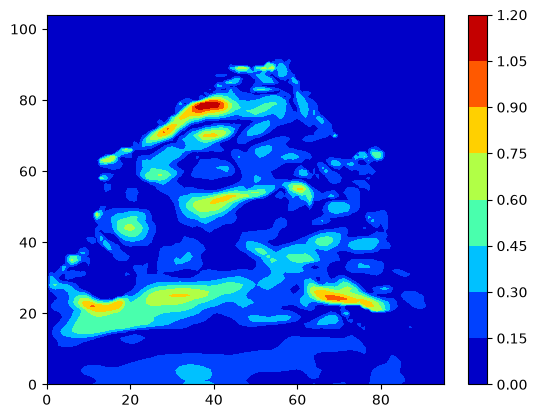

In [6]:
u= dt.u.values[0,-1,:,:]
v= dt.u.values[0,-1,:,:]

velocity=(u**2+v**2)**0.5

m=plt.contourf(velocity, cmap="jet")
plt.colorbar(m)

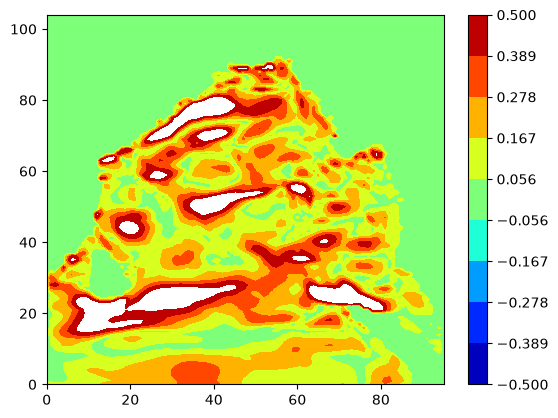

In [8]:
u= dt.u.values[0,-1,:,:]
v= dt.u.values[0,-1,:,:]

velocity=(u**2+v**2)**0.5

m=plt.contourf(velocity, cmap="jet", vmin=-0.5, vmax=0.5, levels=np.linspace(-0.5,0.5,10))
plt.colorbar(m)

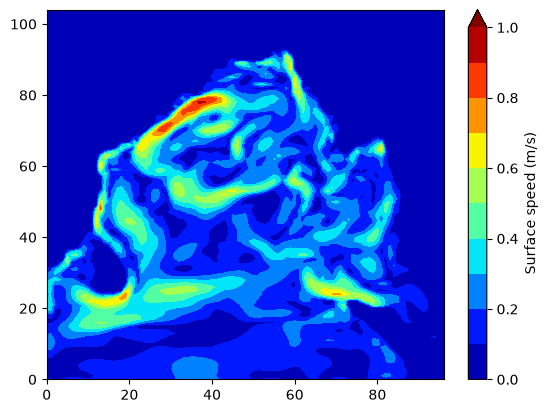

In [10]:
u = dt.u.values[0,-1,:,:]   # (105, 96)
v = dt.v.values[0,-1,:,:]   # (104, 97)

# u -> rho points (xi direction)
u_rho = np.zeros((u.shape[0], u.shape[1] + 1))
u_rho[:, 1:-1] = 0.5 * (u[:, :-1] + u[:, 1:])
u_rho[:, 0]  = u[:, 0]
u_rho[:, -1] = u[:, -1]

# v -> rho points (eta direction)
v_rho = np.zeros((v.shape[0] + 1, v.shape[1]))
v_rho[1:-1, :] = 0.5 * (v[:-1, :] + v[1:, :])
v_rho[0, :]  = v[0, :]
v_rho[-1, :] = v[-1, :]

speed = np.sqrt(u_rho**2 + v_rho**2)

m = plt.contourf(speed, cmap="jet", levels=np.linspace(0, 1, 11), extend="max")
plt.colorbar(m, label="Surface speed (m/s)")
plt.show()


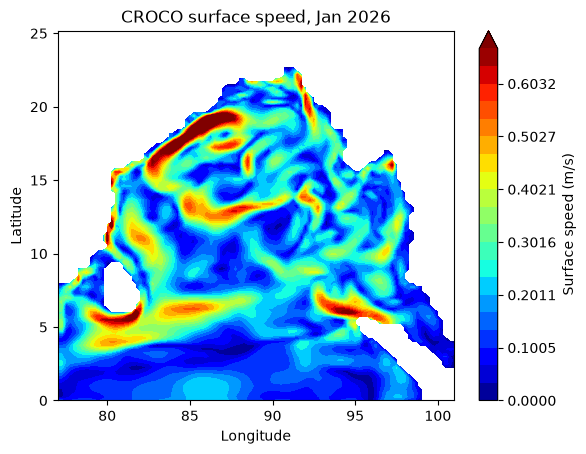

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

dt = xr.open_dataset("croco_avg_Y2026M01.nc")

u = dt.u.values[0, -1, :, :]   # (105, 96)
v = dt.v.values[0, -1, :, :]   # (104, 97)

# u -> rho points (xi direction)
u_rho = np.zeros((u.shape[0], u.shape[1] + 1))
u_rho[:, 1:-1] = 0.5 * (u[:, :-1] + u[:, 1:])
u_rho[:, 0]  = u[:, 0]
u_rho[:, -1] = u[:, -1]

# v -> rho points (eta direction)
v_rho = np.zeros((v.shape[0] + 1, v.shape[1]))
v_rho[1:-1, :] = 0.5 * (v[:-1, :] + v[1:, :])
v_rho[0, :]  = v[0, :]
v_rho[-1, :] = v[-1, :]

speed = np.sqrt(u_rho**2 + v_rho**2)

lon = dt.lon_rho.values
lat = dt.lat_rho.values

# land mask
mask = dt.mask_rho.values
speed = np.where(mask == 1, speed, np.nan)

vmax = np.nanpercentile(speed, 99)
levels = np.linspace(0, vmax, 21)

m = plt.contourf(lon, lat, speed, cmap="jet", levels=levels, extend="max")
plt.colorbar(m, label="Surface speed (m/s)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("CROCO surface speed, Jan 2026")
plt.show()


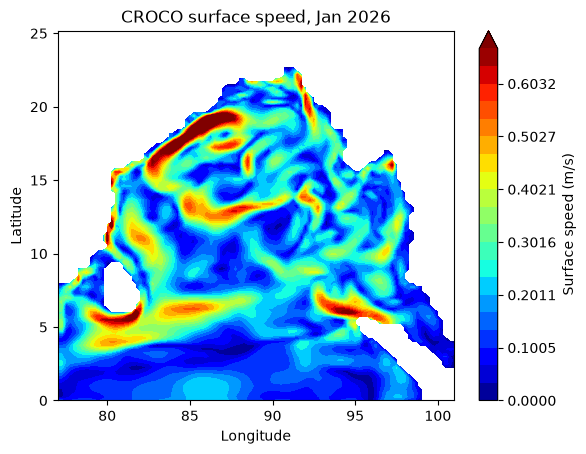

In [13]:
m = plt.contourf(lon, lat, speed, cmap="jet", levels=levels, extend="max")
plt.colorbar(m, label="Surface speed (m/s)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("CROCO surface speed, Jan 2026")

plt.savefig("croco_surface_speed_jan2026.png", dpi=300, bbox_inches="tight")
plt.show()